In [112]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
%matplotlib inline

In [217]:
df = pd.read_excel('saida_controlados_paciente.xlsx')

**Anonimização do Código do Paciente**

In [218]:
# 1. Embaralha as linhas para que a nova numeração não revele a ordem de cadastro no sistema
df_temp = df.sample(frac=1, random_state=42).reset_index(drop=True)

In [219]:
# 2. Gera um ID substituto único para cada código original do sistema
codigos_unicos, _ = pd.factorize(df_temp['Cod_Pac'])
df_temp['Paciente_ID'] = [f"PAC_{i+1:04d}" for i in codigos_unicos]

In [220]:
# 3. Remove a coluna original do sistema antes de salvar a base analítica
df_analitico = df_temp.drop(columns=['Cod_Pac'])

In [221]:
df_analitico.head(15)

,Origem,Cod_Produto,Medicamento,Quantidade,Idade,Gênero,ESF,Val. Médio R$,Val. Total. R$,Paciente_ID
0,FARMACIA MUNICIPAL - FARMACIA,685.0,FLUOXETINA CÁPSULA 20 MG,280.0,NaN,NaN,NaN,0.069000,19.320000,PAC_0001
1,FARMACIA MUNICIPAL - FARMACIA,154.0,IMIPRAMINA CP 25 MG,720.0,NaN,NaN,NaN,0.430000,309.600000,PAC_0002
2,FARMACIA MUNICIPAL - FARMACIA,1017.0,CODEINA CP 30MG,24.0,41.0,M,AGUAPES,1.020000,24.480000,PAC_0003
3,FARMACIA MUNICIPAL - FARMACIA,1017.0,CODEINA CP 30MG,12.0,31.0,M,NaN,1.020000,12.240000,PAC_0004
4,FARMACIA MUNICIPAL - FARMACIA,1017.0,CODEINA CP 30MG,20.0,NaN,NaN,NaN,1.020000,20.400000,PAC_0005
5,FARMACIA MUNICIPAL - FARMACIA,102.0,ACIDO VALPROICO CP 500 MG,350.0,NaN,NaN,NaN,0.553861,193.851351,PAC_0006
6,FARMACIA MUNICIPAL - FARMACIA,685.0,FLUOXETINA CÁPSULA 20 MG,280.0,NaN,NaN,NaN,0.069000,19.320000,PAC_0007
7,FARMACIA MUNICIPAL - FARMACIA,685.0,FLUOXETINA CÁPSULA 20 MG,56.0,NaN,NaN,NaN,0.069000,3.864000,PAC_0008
8,FARMACIA MUNICIPAL - FARMACIA,1008.0,"ALPRAZOLAM CP 0,5 MG",60.0,NaN,NaN,NaN,0.057000,3.420000,PAC_0009
9,FARMACIA MUNICIPAL - FARMACIA,130.0,CARBAMAZEPINA CP 200 MG,900.0,NaN,NaN,NaN,0.165062,148.556212,PAC_0010


In [222]:
df_analitico.drop(columns=['Origem'], inplace=True)

**Classificação dos medicamentos dispensados em classes terapêuticas correspondentes**

In [223]:
#Definindo as classes terapêutica e criando coluna correspondente
condicoes = [
    df_analitico['Medicamento'].str.contains('AMITRIPTILINA|IMIPRAMINA|FLUOXETINA|PAROXETINA|NORTRIPTILINA', case=False, na=False),
    df_analitico['Medicamento'].str.contains('BROMAZEPAM|ALPRAZOLAM|CLONAZEPAM|DIAZEPAM', case=False, na=False),
    df_analitico['Medicamento'].str.contains('CODEINA|MORFINA|TRAMADOL', case=False, na=False),
    df_analitico['Medicamento'].str.contains('FENOBARBITAL|FENITOINA', case=False, na=False),
    df_analitico['Medicamento'].str.contains('CARBAMAZEPINA|ACIDO VALPROICO|VALPROATO DE SODIO', case=False, na=False),
    df_analitico['Medicamento'].str.contains('CARBONATO DE LITIO', case=False, na=False),
    df_analitico['Medicamento'].str.contains('BIPERIDENO', case=False, na=False),
    df_analitico['Medicamento'].str.contains('RISPERIDONA|CLORPROMAZINA|LEVOMEPROMAZINA|HALOPERIDOL|SULPIRIDA|PERICIAZINA|TIORIDAZINA', case=False, na=False)
]

In [224]:
classes = [
    'Antidepressivo',
    'Ansiolítico (Benzodiazepínico)',
    'Analgésico',
    'Anticonvulsivante',
    'Estabilizador humor/anticonvulsivante',
    'Estabilizador humor',
    'Antiparkinsoniano',
    'Neuroléptico'
]

In [225]:
df_analitico['Classe_Terapeutica'] = np.select(condicoes, classes, default='Outros')

**Análise Preliminar**

In [226]:
df_analitico.shape

(11946, 10)

In [227]:
df_analitico.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11946 entries, 0 to 11945
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Cod_Produto         11945 non-null  float64
 1   Medicamento         11945 non-null  object 
 2   Quantidade          11945 non-null  float64
 3   Idade               2243 non-null   float64
 4   Gênero              2243 non-null   object 
 5   ESF                 2004 non-null   object 
 6   Val. Médio R$       11945 non-null  float64
 7   Val. Total. R$      11945 non-null  float64
 8   Paciente_ID         11946 non-null  object 
 9   Classe_Terapeutica  11946 non-null  object 
dtypes: float64(5), object(5)
memory usage: 933.4+ KB


In [228]:
df_analitico.describe()

,Cod_Produto,Quantidade,Idade,Val. Médio R$,Val. Total. R$
count,11945.000000,11945.000000,2243.000000,11945.000000,11945.000000
mean,667.447300,270.075513,49.114133,0.422370,55.480716
std,1261.953695,296.724711,19.728270,1.193818,433.009215
min,100.000000,1.000000,3.000000,0.032364,0.155623
25%,108.000000,60.000000,35.000000,0.057000,8.781854
50%,685.000000,180.000000,50.000000,0.094993,20.400000
75%,1017.000000,360.000000,64.000000,0.270000,52.290000
max,20003.000000,3240.000000,97.000000,19.369000,46368.000000


In [125]:
pip install ydata-profiling

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: C:\Users\nandi\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [229]:
from ydata_profiling import ProfileReport

In [230]:
#Análise dos dados do dataset
profile = ProfileReport(df_analitico, title="Profiling Report", explorative=True)

In [231]:
profile.to_file("relatorio_perfil.html")

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 113.24it/s]


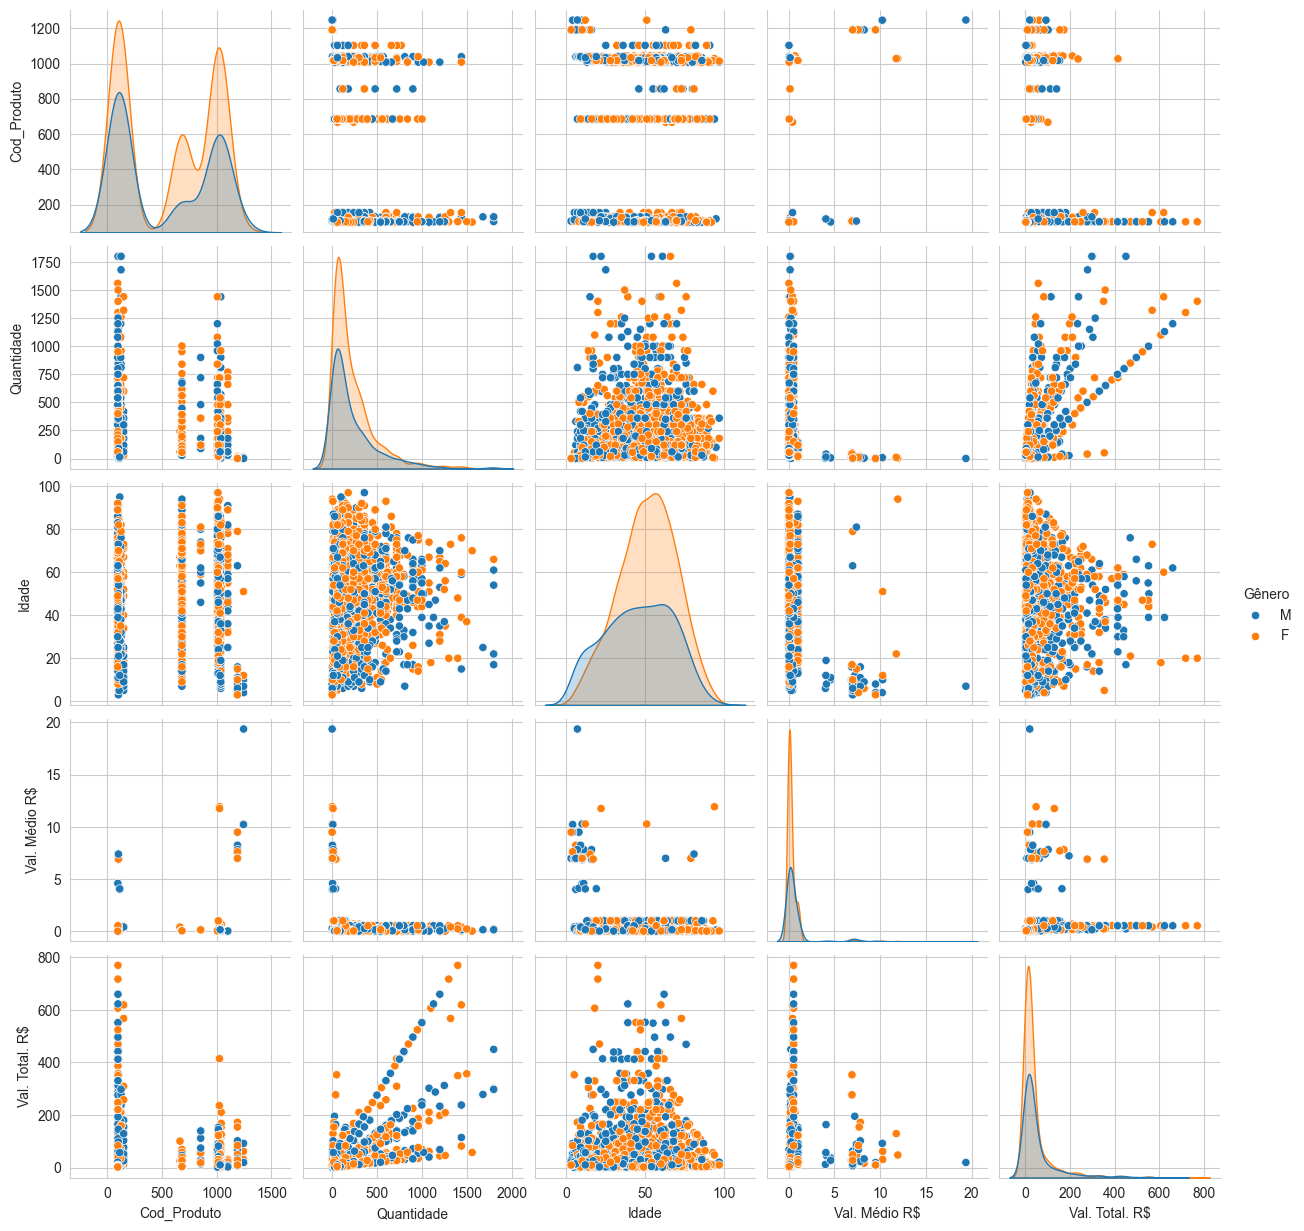

In [232]:
#Analisando os dados através de uma matriz de gráficos de dispersão
sns.set_style('whitegrid')
sns.pairplot(df_analitico, hue='Gênero', height=2.5, aspect=1)
plt.show()

Total de pacientes e % população que utiliza medicamentos psicotrópicos

In [233]:
#Verificando o total de dispensações
df_analitico['Paciente_ID'].nunique()

6428

In [234]:
#Calculando a porcentagem da população que utiliza medicamentos psicotrópicos
porc_pop= df_analitico['Paciente_ID'].nunique()*100/47396
print(f'Porcentagem da população que utiliza medicamentos psicotrópicos: {porc_pop:.2f}%')

Porcentagem da população que utiliza medicamentos psicotrópicos: 13.56%


**Perfil Sociodemográfico dos pacientes que utilizam medicamentos psicotrópicos**

Gênero

In [235]:
#Verificando a quantidade de pacientes de cada gênero
df_analitico['Gênero'].value_counts()

Gênero
F    1372
M     871
Name: count, dtype: int64

In [237]:
#Distribuição do gênero dos pacientes
genero_contagem = df['Gênero'].value_counts().reset_index()
px.pie(genero_contagem, values='count', title='Distribuição de gênero dos pacientes', color_discrete_sequence=['teal','sandybrown'], width=600, height=400, hole=0.3)

Idade

In [238]:
#Calculando média, mediana e moda da idade dos pacientes
media_idade = df_analitico['Idade'].mean()
mediana_idade  = df_analitico['Idade'].median()
moda_idade = df_analitico['Idade'].mode()
print(f'Média de idade dos pacientes: {media_idade:.2f} anos')
print(f'Mediana de idade dos pacientes: {mediana_idade} anos')
print(f'Moda de idade dos pacientes: {moda_idade[0]} anos')

Média de idade dos pacientes: 49.11 anos
Mediana de idade dos pacientes: 50.0 anos
Moda de idade dos pacientes: 62.0 anos


In [239]:
#Histograma para verificar a distribuição da idade dos pacientes
fig = px.histogram(df_analitico, x='Idade', nbins=20, title='Distribuição da Idade dos Pacientes', width=600, height=400, color_discrete_sequence=['teal'])
fig.update_traces(marker_line_color ='black', marker_line_width = 1.5)
fig.show()

Distribuição da Idade por Gênero

In [240]:
#Distribuição da idade por gênero dos pacientes
px.box(df_analitico, x='Gênero', y='Idade', title='Distribuição da idade por gênero', color='Gênero', width=600, height=400)

ESF

In [241]:
#Verificando a quantidade de retiradas por Unidade Básica de Saúde (ESF)
esf = df_analitico['ESF'].value_counts()
esf

ESF
POSTO CENTRAL    374
CARAVAGIO        347
PRIMAVERA        317
LARANJEIRAS      253
ALBATROZ         246
GLORIA           109
AGUAPES          102
ATLANTIDA SUL     81
PALMITAL          58
BORUSSIA          31
EPEN              30
SANTA LUZIA       30
PASSINHOS         26
Name: count, dtype: int64

<Axes: xlabel='ESF'>

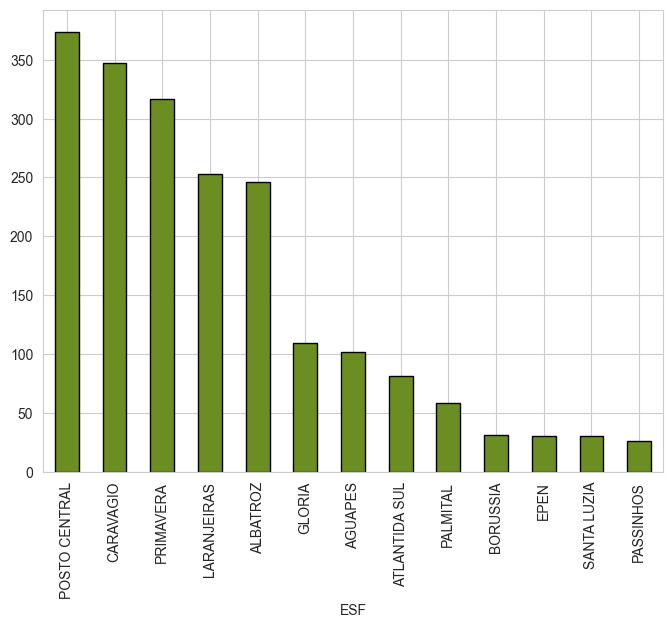

In [242]:
#Gráfico para verificar a quantidade de retiradas por ESF
esf.plot.bar(figsize = (8,6), color='olivedrab', edgecolor='black')

In [243]:
#Relação entre Idade e ESF
df_pacientes_unicos = df_analitico.drop_duplicates(subset=['ESF', 'Paciente_ID'])
media_idade_ESF = df_pacientes_unicos.groupby('ESF')['Idade'].mean()
media_idade_ESF

ESF
AGUAPES          54.127451
ALBATROZ         48.369919
ATLANTIDA SUL    50.425000
BORUSSIA         51.645161
CARAVAGIO        48.198847
EPEN             37.566667
GLORIA           55.899083
LARANJEIRAS      52.146825
PALMITAL         44.655172
PASSINHOS        50.346154
POSTO CENTRAL    53.845946
PRIMAVERA        43.716088
SANTA LUZIA      49.633333
Name: Idade, dtype: float64

In [244]:
#Box-plot para verificar a distribuição da idade dos pacientes por ESF
px.box(df_analitico, x='ESF', y='Idade', color='ESF', title='Distribuição de Idades dos Pacientes por ESF', template='plotly_white')

**Perfil de dispensação de medicamentos psicotrópicos**

**Ranking de medicamentos mais utilizados**

Por número de dispensação (frequência)

In [245]:
#Verificando quantidade de dispensação dos medicamentos por frequência
df_analitico['Medicamento'].value_counts()

Medicamento
FLUOXETINA CÁPSULA 20 MG                   1880
CODEINA CP 30MG                            1225
AMITRIPTILINA CP 25 MG                     1190
PAROXETINA CP 20 MG                        1123
CLONAZEPAM CP 2 MG                          926
RISPERIDONA CP 1 MG                         650
CARBAMAZEPINA CP 200 MG                     575
ACIDO VALPROICO CP 500 MG                   511
CARBONATO DE LITIO CP 300 MG                432
ALPRAZOLAM CP 0,5 MG                        430
CLONAZEPAM CP 0,5 MG                        349
DIAZEPAM  CP 5 MG                           280
IMIPRAMINA CP 25 MG                         252
ACIDO VALPROICO CP 250 MG                   249
BROMAZEPAM CP 3 MG                          241
CLORPROMAZINA CP 25 MG                      231
BIPERIDENO CP 2 MG                          222
LEVOMEPROMAZINA CP 100 MG                   208
RISPERIDONA GTS 1MG/ML - 30 ML              145
FENOBARBITAL CP 100 MG                      137
HALOPERIDOL CP 5 MG         

In [246]:
#Top 10 medicamentos mais dispensados por frequência
top_10_freq = df_analitico['Medicamento'].value_counts().head(10)
top_10_freq

Medicamento
FLUOXETINA CÁPSULA 20 MG        1880
CODEINA CP 30MG                 1225
AMITRIPTILINA CP 25 MG          1190
PAROXETINA CP 20 MG             1123
CLONAZEPAM CP 2 MG               926
RISPERIDONA CP 1 MG              650
CARBAMAZEPINA CP 200 MG          575
ACIDO VALPROICO CP 500 MG        511
CARBONATO DE LITIO CP 300 MG     432
ALPRAZOLAM CP 0,5 MG             430
Name: count, dtype: int64

Por volume total dispensado (soma das quantidades)

In [247]:
#Top 10 medicamentos mais dispensados por quantidade
top_10 = df_analitico.groupby('Medicamento')['Quantidade'].sum().sort_values(ascending=False).head(10)
print(top_10)

Medicamento
FLUOXETINA CÁPSULA 20 MG        392689.0
AMITRIPTILINA CP 25 MG          333129.0
CARBAMAZEPINA CP 200 MG         302000.0
RISPERIDONA CP 1 MG             301976.0
PAROXETINA CP 20 MG             283882.0
ACIDO VALPROICO CP 500 MG       235080.0
CLONAZEPAM CP 2 MG              214824.0
CARBONATO DE LITIO CP 300 MG    195918.0
ALPRAZOLAM CP 0,5 MG            114720.0
ACIDO VALPROICO CP 250 MG       101910.0
Name: Quantidade, dtype: float64


In [248]:
#Gráfico de barras com os medicamentos mais dispensado por quantidade
top_10_df = top_10.reset_index()
px.bar(top_10_df,x='Quantidade', y='Medicamento', orientation='h', title='Top 10 medicamentos mais dispensados',labels={'Medicamento' :''}, text='Quantidade', color='Quantidade', color_continuous_scale='Greens')

In [249]:
#Gráfico de barras com os 10 medicamentos mais utilizados por frequência de dispensação
top_10_freq_df = top_10_freq.reset_index()
px.bar(top_10_freq_df, x='count', y='Medicamento', labels={'count': 'Frequência', 'Medicamento': 'Medicamento'}, title='Top 10 medicamentos mais dispensados por frequência', orientation='h', color_discrete_sequence=['teal'])

Média, mediana e moda das dispensações

In [250]:
#Calculando a média, mediana e moda da quantidade de medicamentos dispensados
Média_disp = df_analitico['Quantidade'].mean().round(2)
Mediana_disp = df_analitico['Quantidade'].median()
Moda_disp = df_analitico['Quantidade'].mode()

print(f'Média de dispensações: {Média_disp}')
print(f'Mediana de dispensações: {Mediana_disp}')
print(f'Moda de dispensações: {Moda_disp}')

Média de dispensações: 270.08
Mediana de dispensações: 180.0
Moda de dispensações: 0    60.0
Name: Quantidade, dtype: float64


Custo total dos tratamentos

In [251]:
#Calculando o custo total, média, mediana e moda do valor total dos medicamentos dispensados
custo_total = df_analitico['Val. Total. R$'].sum()
custo_medio = df_analitico['Val. Total. R$'].mean()
custo_mediano = df_analitico['Val. Total. R$'].median()
custo_moda = df_analitico['Val. Total. R$'].mode()

print(f'Custo total dos tratamentos: R$ {custo_total:.2f}')
print(f'Custo médio dos tratamentos: R$ {custo_medio:.2f}')
print(f'Custo mediano dos tratamentos: R$ {custo_mediano:.2f}')
print(f'Custo mais frequente dos tratamentos: R$ {custo_moda.values[0]:.2f}')

Custo total dos tratamentos: R$ 662717.15
Custo médio dos tratamentos: R$ 55.48
Custo mediano dos tratamentos: R$ 20.40
Custo mais frequente dos tratamentos: R$ 3.86


Medicamentos menos frequentemente dispensado

Por frequência de dispensação

In [252]:
#Verificando medicamentos menos dispensados por frequência
top_5_menos_freq = df_analitico['Medicamento'].value_counts().tail(5)
top_5_menos_freq

Medicamento
HALOPERIDOL INJ 5MG/ML - 1ML       12
TIORIDAZINA CP 50 MG               11
PERICIAZINA ADULTO GTS 4% 20 ML     5
MORFINA AMP 10MG/ML - 1ML           2
TRAMADOL AMP 50MG/ML                1
Name: count, dtype: int64

Por quantidade dispensada

In [253]:
#Verificando os medicamentos menos dispensados por quantidade
top_5_menos_vol = df_analitico.groupby('Medicamento')['Quantidade'].sum().sort_values().head(5)
print(top_5_menos_vol)

Medicamento
TRAMADOL AMP 50MG/ML                   1.0
PERICIAZINA ADULTO GTS 4% 20 ML       11.0
PERICIAZINA PEDIÁTRICO GTS 1% 20ML    66.0
HALOPERIDOL INJ 5MG/ML - 1ML          70.0
CLORPROMAZINA GTS 4% 20ML             78.0
Name: Quantidade, dtype: float64


**Classes Terepêuticas mais utilizadas**

Por frequência

In [254]:
#Verificando as classes terapêutica mais dispensadas por frequência
top_classes = df_analitico['Classe_Terapeutica'].value_counts()
top_classes

Classe_Terapeutica
Antidepressivo                           4560
Ansiolítico (Benzodiazepínico)           2226
Neuroléptico                             1681
Estabilizador humor/anticonvulsivante    1372
Analgésico                               1228
Estabilizador humor                       432
Anticonvulsivante                         224
Antiparkinsoniano                         222
Outros                                      1
Name: count, dtype: int64

In [255]:
#Gráfico para verificar a distribuição das classes terapêuticas mais dispensadas por frequência
top_classes_df = top_classes.reset_index()
px.bar(top_classes_df, x='count', y='Classe_Terapeutica', orientation='h', labels={'count': 'Frequência', 'Classe_Terapeutica': 'Classe Terapêutica'}, title='Top classes terapêuticas mais dispensadas', color_discrete_sequence=['teal'])

Por quantidade dispensada

In [256]:
#Verificando as classes terapêutica mais dispensadas por quantidade
top_classes_quant = df_analitico.groupby('Classe_Terapeutica')['Quantidade'].sum().sort_values(ascending=False)
top_classes_quant

Classe_Terapeutica
Antidepressivo                           1124710.0
Estabilizador humor/anticonvulsivante     639864.0
Neuroléptico                              553688.0
Ansiolítico (Benzodiazepínico)            531736.0
Estabilizador humor                       195918.0
Antiparkinsoniano                          82140.0
Anticonvulsivante                          53794.0
Analgésico                                 44202.0
Outros                                         0.0
Name: Quantidade, dtype: float64

In [257]:
#Gráfico de barras com as classes terapeuticas mais dispensadas por quantidade
top_classes_quant_reset = top_classes_quant.reset_index()
px.bar(top_classes_quant_reset,x='Quantidade', y='Classe_Terapeutica', orientation='h', title='Top classes terapêuticas mais dispensadas',labels={'Medicamento' :''}, text='Quantidade', color='Quantidade', color_continuous_scale='Greens')

Soma total do custo quanto a quantidade dispensada por classe terapêutica

In [258]:
#Calculando o custo total quanto a quantidade por classe terapêutica
soma_classe = df_analitico.groupby('Classe_Terapeutica').agg(quant_total = ('Quantidade', 'sum'),custo_total_classe = ('Val. Total. R$', 'sum'), total_disp = ('Medicamento', 'count')).reset_index()

In [259]:
soma_classe = soma_classe.sort_values(by='custo_total_classe', ascending=False)
soma_classe

,Classe_Terapeutica,quant_total,custo_total_classe,total_disp
6,Estabilizador humor/anticonvulsivante,639864.0,210774.163984,1372
3,Antidepressivo,1124710.0,180339.559808,4560
7,Neuroléptico,553688.0,128751.361912,1681
0,Analgésico,44202.0,45995.834551,1228
5,Estabilizador humor,195918.0,38083.091199,432
1,Ansiolítico (Benzodiazepínico),531736.0,27640.029221,2226
4,Antiparkinsoniano,82140.0,22092.366558,222
2,Anticonvulsivante,53794.0,9040.742652,224
8,Outros,0.0,0.000000,0


In [260]:
resumo_custo_classe = (
    df_analitico.groupby('Classe_Terapeutica')['Val. Total. R$']
    .sum()
    .reset_index(name='Custo_Total')
    .sort_values(by='Custo_Total', ascending=False) # Ordem crescente para o maior ficar no topo
)

In [261]:
#Gráfico de barras para verificar o custo total quanto a quantidade por classe terapêutica
px.bar(resumo_custo_classe, x='Custo_Total', y='Classe_Terapeutica', orientation='h', title='Custo total por Classe Terapêuitica', labels={'Classe_Terapeutica':''}, text='Custo_Total', color='Custo_Total', color_continuous_scale='Greens')

In [262]:
#Percentual de pacientes que retiram múltiplos psicotrópicos
perfil_pacientes = df_analitico.groupby('Paciente_ID').agg(Total_Med_Distintos = ('Medicamento','nunique'), Total_Classes_Distintas = ('Classe_Terapeutica', 'nunique'), Total_Retiradas = ('Medicamento', 'count')).reset_index()

In [263]:
total_pacientes_geral = len(perfil_pacientes)
pacientes_multiplos_meds = perfil_pacientes[perfil_pacientes['Total_Med_Distintos'] > 1]
pacientes_multiplos_classes = perfil_pacientes[perfil_pacientes['Total_Classes_Distintas'] > 1]

In [264]:
perc_multiplos_meds = (len(pacientes_multiplos_meds)/total_pacientes_geral)*100
perc_multiplos_classes = (len(pacientes_multiplos_classes)/ total_pacientes_geral)*100

In [265]:
print(f"Total de pacientes únicos analisados: {total_pacientes_geral}")
print(f"Pacientes com múltiplos medicamentos: {len(pacientes_multiplos_meds)} ({perc_multiplos_meds:.2f}%)")
print(f"Pacientes com múltiplas classes terapêuticas: {len(pacientes_multiplos_classes)} ({perc_multiplos_classes:.2f}%)")

Total de pacientes únicos analisados: 6428
Pacientes com múltiplos medicamentos: 2867 (44.60%)
Pacientes com múltiplas classes terapêuticas: 2512 (39.08%)


In [266]:
dados_grafico = pd.DataFrame({
    'Indicador': [
        'Múltiplos Medicamentos', 
        'Múltiplas Classes Terapêuticas'
    ],
    'Percentual': [
        perc_multiplos_meds, 
        perc_multiplos_classes
    ],
    'Quantidade_Pacientes': [
        len(pacientes_multiplos_meds), 
        len(pacientes_multiplos_classes)
    ]
})

In [267]:
#Gráfico para verificar o percentual de múltiplos medicamentos dos pacientes
px.bar(
    dados_grafico,
    x='Indicador',
    y='Percentual',
    text=dados_grafico['Percentual'].round(2),
    title='Perfil de Polimedicação: % de Pacientes com Uso Múltiplo',
    labels={
        'Indicador': 'Categoria',
        'Percentual': 'Participação (%)'
    },
    color='Indicador',
    template='plotly_white'
)

**Perfil de custos, gênero e classe terapêutica correlacionados**

In [268]:
#Histograma para observar a relação entre os atributos Quantidade, Classe Terapêutica e Gênero
px.histogram(df_analitico, x='Quantidade', y='Classe_Terapeutica', color='Gênero', title='Relação entre a classe terapêutica e gênero dos pacientes', width=900, height=400)

In [269]:
#Box-plot para observar a relação entre os atributos Quantidade, Classe Terapêutica e Idade
px.box(df_analitico, x='Idade', y='Classe_Terapeutica', title='Relação entre a classe terapêutica e idade dos pacientes', width=700, height=400)

In [270]:
# Relação entre Classe Terapêutica e ESF
tabela_esf_med = pd.crosstab(df_analitico['ESF'], df_analitico['Classe_Terapeutica'])

In [271]:
# Transformar a tabela cruzada em formato longo para compatibilidade com o Plotly
tabela_esf_med_longo = tabela_esf_med.stack().reset_index(name='Quantidade')

px.bar(
    tabela_esf_med_longo,
    x='ESF',
    y='Quantidade',
    color='Classe_Terapeutica',
    title='Distribuição das Classes Terapêuticas Mais Frequentes por Unidade de Saúde (ESF)',
    template='plotly_white'
)

In [272]:
#Relação entre medicamentos dispensados e ESF
tabela_med_esf = pd.crosstab(df_analitico['ESF'], df_analitico['Medicamento'], normalize='index')*100
tabela_med_esf.round(2)

Medicamento,ACIDO VALPROICO CP 250 MG,ACIDO VALPROICO CP 500 MG,"ALPRAZOLAM CP 0,5 MG",AMITRIPTILINA CP 25 MG,AMITRIPTILINA CP 75 MG,BIPERIDENO CP 2 MG,BROMAZEPAM CP 3 MG,CARBAMAZEPINA CP 200 MG,CARBAMAZEPINA XPE 100MG/5ML,CARBONATO DE LITIO CP 300 MG,...,LEVOMEPROMAZINA CP 25 MG,LEVOMEPROMAZINA GTS 40MG/ML,NORTRIPTILINA CP 50 MG,PAROXETINA CP 20 MG,PERICIAZINA ADULTO GTS 4% 20 ML,PERICIAZINA PEDIÁTRICO GTS 1% 20ML,RISPERIDONA CP 1 MG,RISPERIDONA GTS 1MG/ML - 30 ML,SULPIRIDA CP 50 MG,VALPROATO DE SODIO XPE 50MG/ML 100ML
ESF,,,,,,,,,,,,,,,,,,,,,
AGUAPES,0.00,4.90,6.86,17.65,0.98,2.94,2.94,2.94,0.00,0.00,...,0.0,0.00,0.00,4.90,0.00,0.00,2.94,1.96,1.96,0.98
ALBATROZ,3.25,7.32,6.10,19.92,0.41,0.81,2.03,4.88,1.22,3.66,...,0.0,0.00,0.41,3.25,0.00,0.41,2.44,2.44,1.63,0.00
ATLANTIDA SUL,2.47,9.88,0.00,23.46,0.00,2.47,0.00,3.70,0.00,2.47,...,0.0,0.00,0.00,4.94,0.00,0.00,3.70,0.00,0.00,0.00
BORUSSIA,0.00,3.23,0.00,25.81,0.00,3.23,0.00,3.23,0.00,3.23,...,0.0,0.00,0.00,3.23,0.00,0.00,3.23,0.00,3.23,0.00
CARAVAGIO,3.17,6.34,10.09,12.10,0.00,0.86,4.61,3.75,0.00,3.46,...,0.0,0.00,0.00,6.63,0.00,0.29,2.31,2.59,0.29,0.00
EPEN,0.00,10.00,0.00,0.00,0.00,0.00,0.00,53.33,0.00,23.33,...,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
GLORIA,3.67,8.26,5.50,11.93,0.92,6.42,3.67,4.59,0.92,2.75,...,0.0,0.00,0.00,7.34,0.00,0.00,0.92,0.92,0.00,0.00
LARANJEIRAS,2.77,5.14,10.67,15.02,0.00,1.98,7.51,2.77,0.00,1.19,...,0.4,0.00,0.40,6.72,0.00,0.79,1.58,0.00,1.58,0.00
PALMITAL,5.17,6.90,3.45,15.52,0.00,0.00,0.00,8.62,0.00,0.00,...,0.0,0.00,0.00,5.17,1.72,0.00,3.45,1.72,0.00,0.00


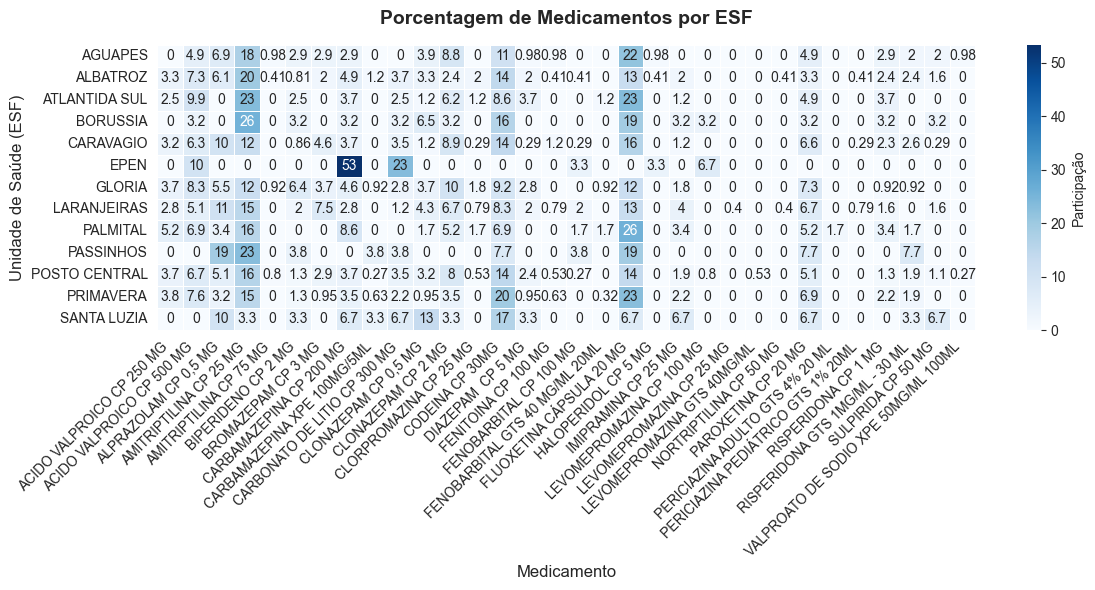

In [273]:
#Mapa de calor para verificar percentual de retirada dos medicamentos por ESF
plt.figure(figsize=(12, 6))
sns.heatmap(
    tabela_med_esf,
    annot=True,          # Mostra os valores nas células
    #fmt='1f',             # Formato float
    cmap='Blues',       # Paleta de cores 
    linewidths=0.5,
    cbar_kws={'label': 'Participação'}
)

plt.title('Porcentagem de Medicamentos por ESF', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Medicamento', fontsize=12)
plt.ylabel('Unidade de Saúde (ESF)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [274]:
#Relação entre Gênero e Valor total gasto
px.box(
    df_analitico,
    x='Gênero',
    y='Val. Total. R$',
    color='Gênero',
    title='Distribuição do Valor Total Dispensado por Gênero',
    template='plotly_white',
    points='outliers'
)

In [275]:
#Teste não paramétrico de Mann-Whitney U para valores gasto entre os gêneros
from scipy.stats import mannwhitneyu

In [276]:
df_limpo = df_analitico.dropna(subset=['Gênero', 'Val. Total. R$'])

In [278]:
grupo_masculino = df_limpo[df_limpo['Gênero'].isin(['M', 'Masculino'])]['Val. Total. R$']
grupo_feminino = df_limpo[df_limpo['Gênero'].isin(['F', 'Feminino'])]['Val. Total. R$']

In [279]:
estatistica_u, p_valor = mannwhitneyu(grupo_masculino, grupo_feminino)
print(f"Estatística U: {estatistica_u:.4f}")
print(f"P-valor (p-value): {p_valor:.4f}")

Estatística U: 669580.5000
P-valor (p-value): 0.0000


In [280]:
alpha = 0.05
if p_valor < alpha:
    print("\nConclusão: Há uma diferença estatisticamente significativa no valor total dispensado entre os gêneros.")
else:
    print("\nConclusão: Não há evidências estatísticas de diferença significativa nos valores totais entre os gêneros.")


Conclusão: Há uma diferença estatisticamente significativa no valor total dispensado entre os gêneros.


In [281]:
#Relação entre valor gasto e ESF
resumo_financeiro_esf = df_analitico.groupby('ESF')['Val. Total. R$'].agg(
    Custo_Total=('sum'),
    Custo_Medio=('mean'),
    Total_Atendimentos=('count')
).reset_index()

In [282]:
resumo_financeiro_esf = resumo_financeiro_esf.sort_values(by='Custo_Total', ascending=False)
resumo_financeiro_esf

,ESF,Custo_Total,Custo_Medio,Total_Atendimentos
10,POSTO CENTRAL,16934.305983,45.278893,374
4,CARAVAGIO,15368.538138,44.289735,347
11,PRIMAVERA,15339.382046,48.389218,317
1,ALBATROZ,13230.182684,53.781230,246
7,LARANJEIRAS,10636.441326,42.041270,253
6,GLORIA,6415.568309,58.858425,109
2,ATLANTIDA SUL,4321.839855,53.356048,81
0,AGUAPES,3428.706790,33.614772,102
8,PALMITAL,2611.100808,45.018979,58
12,SANTA LUZIA,1488.603044,49.620101,30


In [283]:
#Gráfico para verificar distribuição do custo total por ESF
px.bar(
    resumo_financeiro_esf,
    x='Custo_Total',
    y='ESF',
    orientation='h',
    title='Custo Total por Unidade de Saúde (ESF)',
    color_discrete_sequence=['teal'])

In [284]:
#Teste não paramétrico de  Kruskal-Wallis para relação entre valor gasto e ESF
from scipy.stats import kruskal

In [285]:
df_limpo = df.dropna(subset=['ESF', 'Val. Total. R$'])

In [286]:
grupos_esf = [grupo['Val. Total. R$'].values for _, grupo in df_limpo.groupby('ESF')]

In [287]:
estatistica_kw, p_valor = kruskal(*grupos_esf)
print(f"Estatística H (Kruskal-Wallis): {estatistica_kw:.4f}")
print(f"P-valor (p-value): {p_valor:.4f}")

Estatística H (Kruskal-Wallis): 14.5151
P-valor (p-value): 0.2690


In [288]:
alpha = 0.05
if p_valor < alpha:
    print("\nConclusão: Há uma diferença estatisticamente significativa nos valores totais dispensados entre as ESFs.")
else:
    print("\nConclusão: Não há evidências estatísticas de que os custos totais diferem significativamente entre as ESFs.")


Conclusão: Não há evidências estatísticas de que os custos totais diferem significativamente entre as ESFs.


**Implementando um modelo de clusterização (aprendizado não supervisionado) para agrupar as ESFs com base em seus perfis de atendimento**

In [289]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

In [290]:
# 1. Agrupar os dados por ESF para criar o perfil estatístico de cada unidade
perfil_esf = df_analitico.groupby('ESF').agg(
    Idade_Media=('Idade', 'mean'),
    Volume_Dispensacoes=('Medicamento', 'count'),
    Custo_Total=('Val. Total. R$', 'sum'),
    Custo_Medio_Por_Atendimento=('Val. Total. R$', 'mean')
).reset_index()

In [291]:
# 2. Selecionar as variáveis numéricas que servirão de base para o agrupamento
features = ['Idade_Media', 'Volume_Dispensacoes', 'Custo_Total', 'Custo_Medio_Por_Atendimento']
X = perfil_esf[features]

In [292]:
# 3. Padronizar as variáveis (normalização z-score) para que escalas diferentes 
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [293]:
# 4. Testar diferentes quantidades de clusters (de 1 a 10)
inercia = []
intervalo_k = range(1, 11)

In [294]:
for k in intervalo_k:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_) # Guarda a inércia (soma dos erros quadráticos)

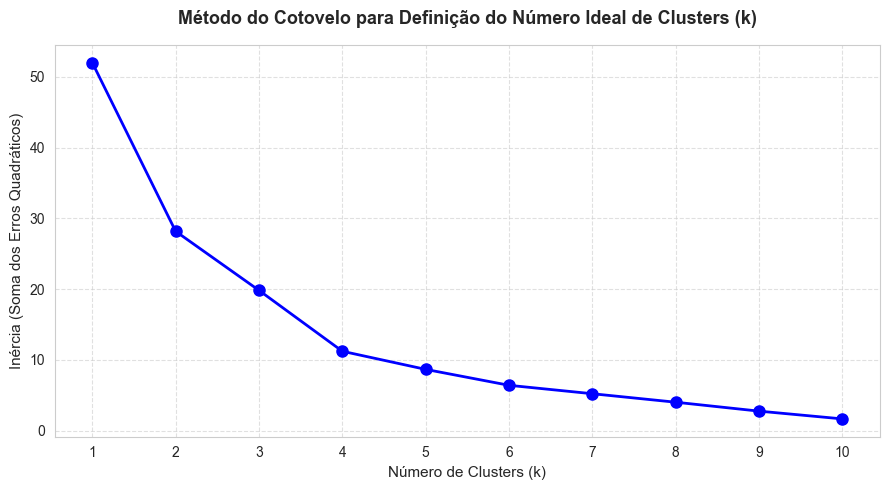

In [295]:
# Plotar o Gráfico do Cotovelo
plt.figure(figsize=(9, 5))
plt.plot(intervalo_k, inercia, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Método do Cotovelo para Definição do Número Ideal de Clusters (k)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Número de Clusters (k)', fontsize=11)
plt.ylabel('Inércia (Soma dos Erros Quadráticos)', fontsize=11)
plt.xticks(intervalo_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

In [296]:
# 5. Aplicar o K-Means (definindo 3 clusters/perfis diferentes)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
perfil_esf['Cluster'] = kmeans.fit_predict(X_scaled)

In [297]:
print("Perfis das ESFs agrupados por Cluster:")
print(perfil_esf.to_string(index=False))

Perfis das ESFs agrupados por Cluster:
          ESF  Idade_Media  Volume_Dispensacoes  Custo_Total  Custo_Medio_Por_Atendimento  Cluster
      AGUAPES    54.127451                  102  3428.706790                    33.614772        0
     ALBATROZ    48.369919                  246 13230.182684                    53.781230        1
ATLANTIDA SUL    50.358025                   81  4321.839855                    53.356048        0
     BORUSSIA    51.645161                   31  1278.601762                    41.245218        0
    CARAVAGIO    48.198847                  347 15368.538138                    44.289735        1
         EPEN    37.566667                   30  1117.861788                    37.262060        2
       GLORIA    55.899083                  109  6415.568309                    58.858425        0
  LARANJEIRAS    52.146825                  253 10636.441326                    42.041270        1
     PALMITAL    44.655172                   58  2611.100808          

In [298]:
px.scatter(
    perfil_esf,
    x='Volume_Dispensacoes',
    y='Idade_Media',
    color='Cluster',
    text='ESF',
    size='Custo_Total',
    title='Clusterização das Unidades de Saúde (ESF) por Perfil de Atendimento',
    labels={
        'Volume_Dispensacoes': 'Volume Total de Dispensações',
        'Idade_Media': 'Idade Média dos Pacientes (Anos)'
    },
    template='plotly_white'
)